In [10]:
#libaries

import json
import pandas as pd
import geopandas as gpd
from shapely.geometry import shape
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
walk = pd.read_csv("shelby-county-walkability-index0.csv")
walk = walk.rename(columns={
    'walkabilty_index': 'Walkability_Index',
    'Census block group 12-digit FIPS code (2018)': 'GEOID',
    'Population, 2018': 'Population_2018'
})

walk['geometry'] = walk['the_geom'].apply(lambda s: shape(json.loads(s)))
walk_gdf = gpd.GeoDataFrame(walk, geometry='geometry', crs="EPSG:4326")

print("block groups:", len(walk_gdf))

block groups: 628


In [12]:
#clean data

crime = pd.read_csv("MPD_Public_Safety_Incidents_7082481021792316866.csv")

#convert date text into real dates unreadable become blank
crime['Offense Datetime'] = pd.to_datetime(crime['Offense Datetime'], format="%m/%d/%Y %I:%M:%S %p", errors='coerce')
print("raw rows:", len(crime))

#2022-2024 years skips COVID years and the South Cordova de-annexation
crime = crime[(crime['Offense Datetime'] >= '2022-01-01') & (crime['Offense Datetime'] < '2025-01-01')]

#drop rows stamped at 0,0 
crime = crime[(crime['Latitude'] != 0) & (crime['Longitude'] != 0)]

#one report can be split across several rows keep one 
crime = crime.drop_duplicates(subset='Crime ID')

print("reports kept:", len(crime))

raw rows: 659839
reports kept: 293624


In [13]:
#turn lat/long into points
crime_gdf = gpd.GeoDataFrame(
    crime,
    geometry=gpd.points_from_xy(crime['Longitude'], crime['Latitude']),
    crs="EPSG:4326"
)

#spatial join: find which block group each report falls inside
joined = gpd.sjoin(crime_gdf, walk_gdf[['GEOID', 'geometry']], how="inner", predicate="within")
print("reports outside every block group:", len(crime_gdf) - len(joined))

reports outside every block group: 2


In [16]:
#count how many reports landed in each block group
counts = joined.groupby('GEOID').size().reset_index(name='incident_count')

#attach those counts to the walkability table
#"inner" keeps only block groups that have MPD reports
#this is what drops Germantown, Collierville, etc. (they have their own police, so no MPD data)
merged = walk.merge(counts, on='GEOID', how='inner')

#drop block groups with 0 residents, since you can't divide by zero
merged = merged[merged['Population_2018'] > 0].copy()

#reports per 1,000 residents, so big and small block groups can be compared fairly
merged['incidents_per_1000'] = merged['incident_count'] / merged['Population_2018'] * 1000

print("block groups in analysis:", len(merged), "of", len(walk))   # expect a bit under 560

#optional: drop block groups that barely touch MPD's area (talk to your partner first)
#merged = merged[merged['incident_count'] >= 20]

block groups in analysis: 547 of 628


In [30]:
#Spearman (rank-based, handles outliers)
rho, p_s = spearmanr(merged['Walkability_Index'], merged['incidents_per_1000'])

#Pearson for comparison (straight-line relationship)
r, p_p = pearsonr(merged['Walkability_Index'], merged['incidents_per_1000'])

print(f"Spearman rho = {rho:.3f}, p = {p_s:.4f}")
print(f"Pearson r = {r:.3f}, p = {p_p:.4f}")

#drop edge block groups that are mostly outside MPD area
clean = merged[merged['incident_count'] >= 20].copy()
print("dropped:", len(merged) - len(clean))
print("cleaned:", spearmanr(clean['Walkability_Index'], clean['incidents_per_1000']))

Spearman rho = 0.530, p = 0.0000
Pearson r = 0.122, p = 0.0043
dropped: 37
cleaned: SignificanceResult(statistic=np.float64(0.48347033062740025), pvalue=np.float64(3.1096194333387725e-31))


In [23]:
#count reports per block group, split by type
#(crimes against persons / property / society), one column per type
joined = joined[joined['NIBRS Offense Group'].isin(['CRIMES AGAINST PERSONS', 'CRIMES AGAINST PROPERTY', 'CRIMES AGAINST SOCIETY'])]
by_type = joined.groupby(['GEOID', 'NIBRS Offense Group']).size().unstack(fill_value=0).reset_index()

#fillna(0) = a block group with no reports of a type gets 0 for that type
typed = merged[['GEOID', 'Walkability_Index', 'Population_2018']].merge(by_type, on='GEOID', how='left').fillna(0)

# run Spearman separately for each crime type
for col in by_type.columns.drop('GEOID'):                    # loop through each crime type column
    rate = typed[col] / typed['Population_2018'] * 1000      # that type's reports per 1,000 residents
    rho_t, p_t = spearmanr(typed['Walkability_Index'], rate)
    print(f"{col}: rho = {rho_t:.3f}, p = {p_t:.4f}")

CRIMES AGAINST PERSONS: rho = 0.381, p = 0.0000
CRIMES AGAINST PROPERTY: rho = 0.556, p = 0.0000
CRIMES AGAINST SOCIETY: rho = 0.443, p = 0.0000


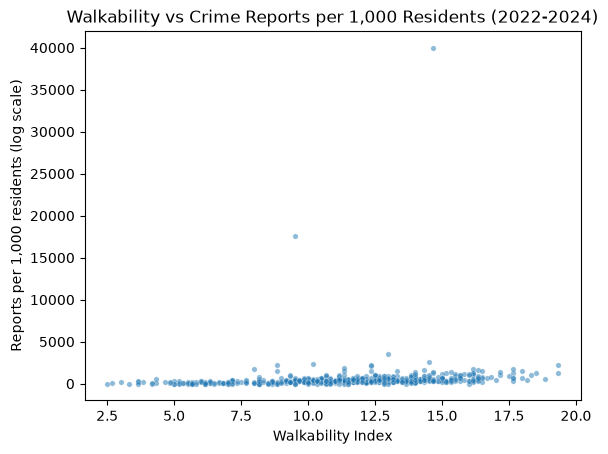

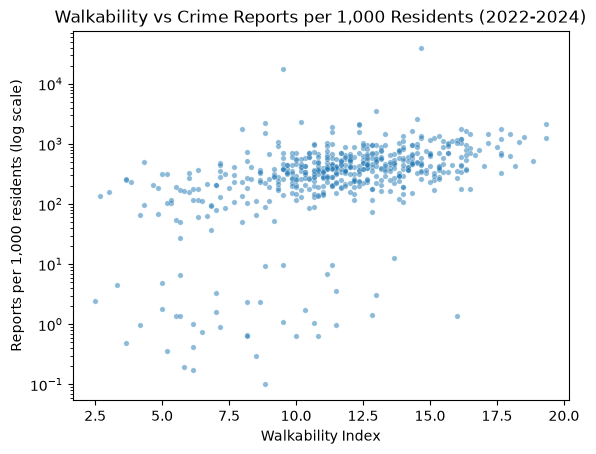

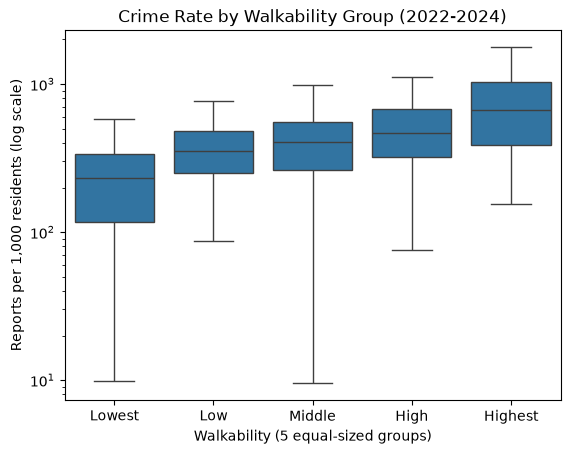

In [45]:
# scatter plot: one dot per block group
ax = sns.scatterplot(x='Walkability_Index', y='incidents_per_1000', data=merged, alpha=0.5, s= 15)
plt.title("Walkability vs Crime Reports per 1,000 Residents (2022-2024)")
plt.xlabel("Walkability Index")
plt.ylabel("Reports per 1,000 residents (log scale)")
plt.show()

#log
ax = sns.scatterplot(x='Walkability_Index', y='incidents_per_1000', data=merged, alpha=0.5, s=15)
ax.set_yscale('log')
plt.title("Walkability vs Crime Reports per 1,000 Residents (2022-2024)")
plt.xlabel("Walkability Index")
plt.ylabel("Reports per 1,000 residents (log scale)")
plt.show()
plt.show()

#box
clean['walk_group'] = pd.qcut(clean['Walkability_Index'], 5, labels=['Lowest', 'Low', 'Middle', 'High', 'Highest'])
ax = sns.boxplot(x='walk_group', y='incidents_per_1000', data=clean, showfliers=False)
ax.set_yscale('log')
plt.title("Crime Rate by Walkability Group (2022-2024)")
plt.xlabel("Walkability (5 equal-sized groups)")
plt.ylabel("Reports per 1,000 residents (log scale)")
plt.show()

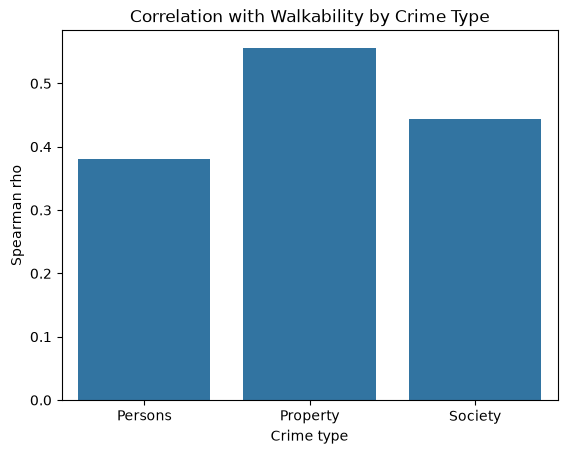

In [35]:
types = ['CRIMES AGAINST PERSONS', 'CRIMES AGAINST PROPERTY', 'CRIMES AGAINST SOCIETY']
results = []
for col in types:
    rate = typed[col] / typed['Population_2018'] * 1000
    rho_t, p_t = spearmanr(typed['Walkability_Index'], rate)
    results.append({'Crime type': col.replace('CRIMES AGAINST ', '').title(), 'rho': rho_t})
res = pd.DataFrame(results)

sns.barplot(x='Crime type', y='rho', data=res)
plt.title("Correlation with Walkability by Crime Type")
plt.ylabel("Spearman rho")
plt.show()